<a href="https://colab.research.google.com/github/manojmenon1/CICD-MLOps-Final-Proj/blob/main/Nestle_HR_Assistant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Crafting an AI-Powered HR Assistant: A Use Case for Nestle’s HR Policy Documents
## Course-end Project 1
### Description

### Overview

The project aims to create a conversational chatbot that responds to user inquiries using PDF document information. It requires proficiency in extracting and converting text into numerical vectors, establishing an answer-finding mechanism, and designing a user-friendly chatbot interface with Gradio. Additionally, the initiative emphasizes structuring inquiries for clear communication and deploying the chatbot for practical use, guaranteeing the system's accessibility and efficiency in meeting user needs.

### Instructions

Review the learning materials and the Gradio documentation provided for the project.
Read the sections on situation, task, action, and result carefully to understand the assignment.
Complete and submit the assignment through the Learning Management System (LMS).
Adhere closely to the provided guidelines, ensuring your submission contains all necessary analyses and interpretations.

### Situation

As a developer, you have received the critical task of improving the operational efficiency of Nestlé's human resources department, a leading multinational corporation. Your toolkit includes cutting-edge conversational AI technology, Python libraries, the powerful GPT model from OpenAI, and the user-friendly Gradio UI. Your mission is to integrate these advanced tools seamlessly to transform HR processes, creating a more streamlined and efficient workflow within the Nestlé organization.

# Setup

%pip install -q --upgrade tiktoken pypdf langchain langchain-community langchain-text-splitters chromadb sentence-transformers groq gdown

In [ ]:
%%capture
%pip install -q langchain-community chromadb groq

In [ ]:
%%capture
%pip install -q pypdf

In [ ]:
%%capture
%pip install -q --upgrade chromadb opentelemetry-api

In [ ]:
%%capture
%pip uninstall -y opentelemetry-api chromadb

In [ ]:
%%capture
%pip install -q opentelemetry-api

In [ ]:
%%capture
%pip install -q chromadb

In [ ]:
%pip install -q -U langchain-huggingface huggingface-hub

In [ ]:
import importlib.metadata as md
import importlib

required = [
    ("tiktoken", "tiktoken"),
    ("pypdf", "pypdf"),
    ("langchain", "langchain"),
    ("langchain-community", "langchain_community"),
    ("chromadb", "chromadb"),
    ("sentence-transformers", "sentence_transformers"),
    ("groq", "groq"),
    ("gdown", "gdown"),
]

print("Package check:")
all_ok = True
for pkg, module_name in required:
    try:
        installed = md.version(pkg)
        print(f"- {pkg}: installed={installed}")
    except md.PackageNotFoundError:
        print(f"- {pkg}: NOT INSTALLED")
        all_ok = False

print("\nImport check:")
for pkg, module_name in required:
    try:
        importlib.import_module(module_name)
        print(f"- {pkg} ({module_name}): IMPORT OK")
    except Exception as e:
        print(f"- {pkg} ({module_name}): IMPORT FAILED -> {type(e).__name__}: {e}")
        all_ok = False

print("\nFINAL:", "READY" if all_ok else "NOT READY")

Package check:
- tiktoken: installed=0.12.0
- pypdf: installed=6.10.2
- langchain: installed=1.2.15
- langchain-community: installed=0.4.1
- chromadb: installed=1.5.8
- sentence-transformers: installed=5.4.1
- groq: installed=1.2.0
- gdown: installed=5.2.2

Import check:
- tiktoken (tiktoken): IMPORT OK
- pypdf (pypdf): IMPORT OK
- langchain (langchain): IMPORT OK
- langchain-community (langchain_community): IMPORT OK
- chromadb (chromadb): IMPORT OK
- sentence-transformers (sentence_transformers): IMPORT OK
- groq (groq): IMPORT OK
- gdown (gdown): IMPORT OK

FINAL: READY


%pip install -q -U langchain-huggingface huggingface-hub

In [ ]:
import importlib

importlib.import_module("langchain_huggingface")
importlib.import_module("huggingface_hub")

print("langchain-huggingface and huggingface-hub are installed and importable.")

langchain-huggingface and huggingface-hub are installed and importable.


# Restart the Kernal Before Executing the below cells "if pip install was run prior to the below steps".

In [ ]:
import json
import tiktoken
import gdown

import pandas as pd

from langchain_text_splitters import RecursiveCharacterTextSplitter

from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_community.embeddings.sentence_transformer import (
    SentenceTransformerEmbeddings
)
from langchain_community.vectorstores import Chroma

In [ ]:
from pathlib import Path

# Find PDF files in the same folder as this notebook
pdf_files = sorted(Path(".").glob("*.pdf"))

if not pdf_files:
    raise FileNotFoundError("No PDF file found in the current notebook folder.")

if len(pdf_files) > 1:
    print(f"Multiple PDFs found. Using the first one: {pdf_files[0].name}")

# Use current folder with existing PyPDFDirectoryLoader logic
pdf_folder_location = "."
pdf_loader = PyPDFDirectoryLoader(pdf_folder_location)

# Optional: load now to verify it works
documents = pdf_loader.load()
print(f"Loaded {len(documents)} pages from PDF(s) in: {Path(pdf_folder_location).resolve()}")

Loaded 8 pages from PDF(s) in: /content


In [ ]:
pdf_file_name = "the_nestle_hr_policy_pdf_2012.pdf"
pdf_folder_location = "."

pdf_loader = PyPDFDirectoryLoader(pdf_folder_location)
documents = pdf_loader.load()

documents = [
    d for d in documents
    if d.metadata.get("source", "").endswith(pdf_file_name)
]

if not documents:
    raise FileNotFoundError(f"{pdf_file_name} not found in {pdf_folder_location}")

print(f"Loaded {len(documents)} pages from: {pdf_file_name}")

Loaded 8 pages from: the_nestle_hr_policy_pdf_2012.pdf


%pip install -q gdown

In [ ]:
import gdown

# Creating a Vector Database

## Download Raw Data

## Chunking

Once the choice of embedding model is made, we can feed the input documents to the model. However, since there are multiple pages across documents (including figures, tables) we will need a method to parse individual portions of the document that is aligned with the embedding model.

We also know that the embedding model cannot process text beyond a fixed context length (512 tokens for `gte-large`). This roughly corresponds to about 400 words or about 1 page of text. With this limitation in mind, we will transform the pdf file into chunks of text that are no more than 512 characters long (this is a conservative choice from a token perspective). An alternative method would be to chunk the file by sections in the report (e.g., risk factors, legal proceedings, safety disclosures).

A common chunking strategy is to used a fixed-size chunk as defined by the embedding model and use a small overlap between the chunks (see figure below). Note that the chunk size is number of characters and not number of tokens.


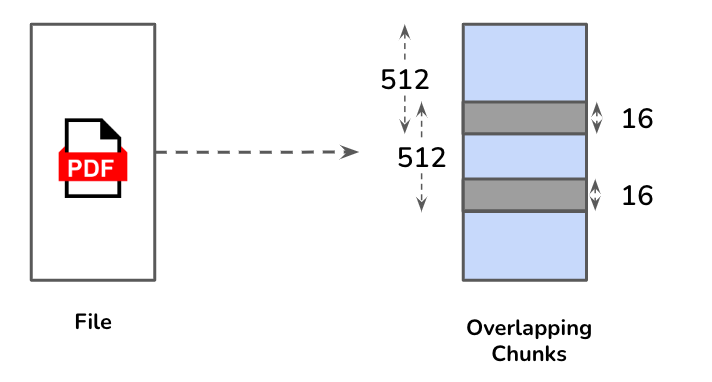

Using an overlap allows for continuity between chunks and retrieval of relevant chunks even when the information relevant to the query is present either at the beginning of the chunk or the end of the chunk.

pdf_folder_location = "tesla-annual-reports"

pdf_loader = PyPDFDirectoryLoader(pdf_folder_location)

from langchain_community.document_loaders import PyPDFDirectoryLoader

pdf_loader = PyPDFDirectoryLoader(pdf_folder_location)
print(f"pdf_loader created for: {pdf_folder_location}")

import importlib
importlib.import_module("langchain_community")

from langchain_community.document_loaders import PyPDFDirectoryLoader

pdf_folder_location = "tesla-annual-reports"
pdf_loader = PyPDFDirectoryLoader(pdf_folder_location)
print(f"langchain_community is available. pdf_loader ready for: {pdf_folder_location}")

In [ ]:
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name='cl100k_base',
    chunk_size=512,
    chunk_overlap=16
)

In [ ]:
tesla_10k_chunks = pdf_loader.load_and_split(text_splitter)

In [ ]:
len(tesla_10k_chunks)

10

## Database Creation

In [ ]:
tesla_10k_collection = 'the_nestle_hr_policy_pdf_2012'

%pip install -q -U langchain-huggingface huggingface-hub

In [ ]:
import os
from langchain_huggingface import HuggingFaceEmbeddings
from huggingface_hub import login




hf_token = os.getenv("HF_TOKEN")
if hf_token:
    login(token=hf_token, add_to_git_credential=False)
else:
    print("HF_TOKEN not set. Downloads will still work, but HF Hub may warn about unauthenticated requests.")

# Make later cells use the updated embeddings class without changing their code
SentenceTransformerEmbeddings = HuggingFaceEmbeddings
print("Configured SentenceTransformerEmbeddings to use langchain_huggingface.HuggingFaceEmbeddings.")

HF_TOKEN not set. Downloads will still work, but HF Hub may warn about unauthenticated requests.
Configured SentenceTransformerEmbeddings to use langchain_huggingface.HuggingFaceEmbeddings.


In [ ]:
embedding_model = SentenceTransformerEmbeddings(model_name='thenlper/gte-large')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/619 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

In [ ]:
vectorstore = Chroma.from_documents(
    tesla_10k_chunks,
    embedding_model,
    collection_name=tesla_10k_collection,
    persist_directory='./tesla_db'
)

In [ ]:
vectorstore.persist()

/tmp/ipykernel_4599/398866168.py:1: LangChainDeprecationWarning: Since Chroma 0.4.x the manual persistence method is no longer supported as docs are automatically persisted.
  vectorstore.persist()


In [ ]:
#Loading the Chroma DB and using the retriever to retreive the chunks just for testing

In [ ]:
vectorstore_persisted = Chroma(
    collection_name=tesla_10k_collection,
    persist_directory='./tesla_db',
    embedding_function=embedding_model
)

/tmp/ipykernel_4599/377671238.py:1: LangChainDeprecationWarning: The class `Chroma` was deprecated in LangChain 0.2.9 and will be removed in 1.0. An updated version of the class exists in the `langchain-chroma package and should be used instead. To use it run `pip install -U `langchain-chroma` and import as `from `langchain_chroma import Chroma``.
  vectorstore_persisted = Chroma(


In [ ]:
retriever = vectorstore_persisted.as_retriever(
    search_type='similarity',
    search_kwargs={'k': 5}
)

In [ ]:
query = "What are the key benefits provided by the Nestle HR policy?"

In [ ]:
docs = vectorstore_persisted.similarity_search(query, k=5)

In [ ]:
for i, doc in enumerate(docs):
    print(f"Retrieved chunk {i+1}: \n")
    print(doc.page_content.replace('\t', ' '))
    print('\n')

Retrieved chunk 1: 

The Nestlé Human Resources Policy
3
 Total rewards
Attracting new hires and keeping current 
employees engaged is not only about 
remuneration and benefits based on solid 
performance. It is also about the hard earned 
value and trust that our name brings to those 
who work with us; the relationships with our line 
managers and fellow workers; recognition and 
experiences enjoyed while working for a diverse 
global company; and possibilities to learn and 
grow. These are as a whole, the Total Rewards we 
receive.
Nestlé, therefore, focuses on Fixed Pay, 
Variable Pay, Benefits, Personal Growth and 
Development and Work Life Environment as the 
key elements that define Total Rewards. In the 
spirit of developing a high performance culture, 
those elements need to correspond to what is 
valued by employees in each and every market, 
and which demonstrate how Nestlé is committed 
to giving each employee the opportunity to grow, 
evolve and contribute.
Nestlé Total Rew

In [ ]:
import json
import tiktoken

import pandas as pd

from openai import AzureOpenAI

from langchain_text_splitters import RecursiveCharacterTextSplitter

from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_community.embeddings.sentence_transformer import (
    SentenceTransformerEmbeddings
)
from langchain_community.vectorstores import Chroma

In [ ]:
from google.colab import userdata
import os
from groq import Groq
from google.colab import userdata # For secure API key handling

# Set your API key from Colab Secrets
os.environ["GROQ_API_KEY"] = userdata.get('GROQ_API_KEY')

client = Groq()
model_name='openai/gpt-oss-120b'

In [ ]:
embedding_model = SentenceTransformerEmbeddings(model_name='thenlper/gte-large')

/tmp/ipykernel_4599/4198310515.py:1: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  embedding_model = SentenceTransformerEmbeddings(model_name='thenlper/gte-large')


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

BertModel LOAD REPORT from: thenlper/gte-large
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
tesla_10k_collection = 'the_nestle_hr_policy_pdf_2012'

In [ ]:
vectorstore_persisted = Chroma(
    collection_name=tesla_10k_collection,
    persist_directory='./tesla_db',
    embedding_function=embedding_model
)

In [ ]:
retriever = vectorstore_persisted.as_retriever(
    search_type='similarity',
    search_kwargs={'k': 5}
)

In [ ]:
# Retrieve the first two chunks from the vector store
retrieved_data = vectorstore_persisted.get(
    include=['metadatas', 'embeddings', 'documents'],
    limit=2
)

# Display the content and embeddings of the first two chunks
for i in range(len(retrieved_data['ids'])):
    print(f"Chunk ID: {retrieved_data['ids'][i]}")
    print(f"Chunk Content: {retrieved_data['documents'][i]}")
    print(f"Chunk Embedding (first 10 values): {retrieved_data['embeddings'][i][:10]}")
    print("\n")

Chunk ID: 6de2fccf-dc32-4306-bd01-555a0e546c6f
Chunk Content: Policy
Mandatory
September   2012
The Nestlé  
Human Resources Policy
Chunk Embedding (first 10 values): [-0.0249939  -0.01151276 -0.01689148  0.00250244 -0.00569153  0.01158905
 -0.00780106  0.01454926 -0.01490021  0.00474167]


Chunk ID: d59750be-793e-41e7-9ad1-dc6818d1853c
Chunk Content: Policy
Mandatory
September 
 20
12
Issuing  departement
Hum
an Resources
T arget  audience  
All
 employees
Approver
Executive Board, Nestlé S.A.
Repository
All Nestlé Principles and Policies, Standards and  
Guidelines can be found in the Centre online repository at:  
http://intranet.nestle.com/nestledocs
Copyright
 and  confidentiality
Al
l rights belong to Nestec Ltd., Vevey, Switzerland.
© 2012, Nestec Ltd.
Design
Nestec Ltd., Corporate Identity & Design,  
Vevey, Switzerland
Production
brain’print GmbH, Switzerland
Paper
This report is printed on BVS, a paper produced  
from well-managed forests and other controlled sources  
certif

## RAG Q&A

### Prompt Design

In [ ]:
qna_system_message = """
You are an HR assistant to a Nestle Company who answers user queries on HR policies.
User input will have the context required by you to answer user questions.
This context will begin with the token: ###Context.
The context contains references to specific portions of a document relevant to the user query.

User questions will begin with the token: ###Question.

Please answer user questions only using the context provided in the input.
Do not mention anything about the context in your final answer. Your response should only contain the answer to the question.

If the answer is not found in the context, respond "I don't know".
"""

In [ ]:
qna_user_message_template = """
###Context
Here are some documents that are relevant to the question mentioned below.
{context}

###Question
{question}
"""

### Retrieving relevant documents

In [ ]:
user_input = "What are the Talent Development programs at Nestle?"

In [ ]:
relevant_document_chunks = retriever.invoke(user_input)

In [ ]:
len(relevant_document_chunks)

5

In [ ]:
for document in relevant_document_chunks:
    print(document.page_content.replace("\t", " "))
    break

necessary time to the monitoring of objectives and 
regular coaching of employees through the year. 
Each employee, supported by the line manager, 
is in charge of her or his own professional 
development, whereby the employee is 
encouraged to express career objectives and 
expectations in an open dialogue. We aim to retain 
and motivate employees by offering attractive but 
realistic career moves allowing them to develop 
their skills in the long-term.
Given the importance Nestlé puts on cultural 
diversity, employees who are interested in inter-
national assignments can be given the opportunity 
to work in different countries. The international 
dimension of the Group is used as a competitive 
advantage to retain and develop talented people.
At Nestlé, promotions are based on sustained 
performance from a results and behaviour 
standpoint, as well as future potential. The 
Company undertakes an active and rigorous 
succession planning process at all levels of the 
organisation to en

### Composing the response

In [ ]:
user_input = "What are the Talent Development programs at Nestle?"

In [ ]:
relevant_document_chunks = retriever.invoke(user_input)
context_list = [d.page_content for d in relevant_document_chunks]
context_for_query = ". ".join(context_list)

prompt = [
    {'role':'system', 'content': qna_system_message},
    {'role': 'user', 'content': qna_user_message_template.format(
         context=context_for_query,
         question=user_input
        )
    }
]

response = client.chat.completions.create(
    model='llama-3.3-70b-versatile',
    messages=prompt
    )

answer = response.choices[0].message.content
print(answer)

At Nestle, talent development programs include on-the-job training, lateral professional development, extension of responsibilities, cross-functional teams, and a comprehensive range of training activities and methodologies. Additionally, the company offers corporate leadership programs, such as international training courses at Rive-Reine, which build integrated business understanding and solidify Nestle values and principles. Employees are also encouraged to attend programs conducted by strategic learning partners. Experience and on-the-job training are the primary source of learning, and managers are responsible for guiding and coaching employees to succeed in their current positions.


In [ ]:
prompt

[{'role': 'system',
  'content': '\nYou are an HR assistant to a Nestle Company who answers user queries on HR policies.\nUser input will have the context required by you to answer user questions.\nThis context will begin with the token: ###Context.\nThe context contains references to specific portions of a document relevant to the user query.\n\nUser questions will begin with the token: ###Question.\n\nPlease answer user questions only using the context provided in the input.\nDo not mention anything about the context in your final answer. Your response should only contain the answer to the question.\n\nIf the answer is not found in the context, respond "I don\'t know".\n'},
 {'role': 'user',
  'content': '\n###Context\nHere are some documents that are relevant to the question mentioned below.\nnecessary time to the monitoring of objectives and \nregular coaching of employees through the year. \nEach employee, supported by the line manager, \nis in charge of her or his own professiona

## Evaluation

Let us now use the LLM-as-a-judge method to check the quality of the RAG system on two parameters - retrieval and generation. We illustrate this evaluation based on the answeres generated to the question from the previous section.

In [ ]:
rater_model = 'openai/gpt-oss-120b'

To save cost, we are using GPT 3.5 itself as the judge, the ideal choice would have been GPT 4 (note that this will impact the quality of the evaluation).

In [ ]:
groundedness_rater_system_message = """
You are tasked with rating AI generated answers to questions posed by users.
You will be presented a question, context used by the AI system to generate the answer and an AI generated answer to the question.
In the input, the question will begin with ###Question, the context will begin with ###Context while the AI generated answer will begin with ###Answer.

Evaluation criteria:
The task is to judge the extent to which the metric is followed by the answer.
1 - The metric is not followed at all
2 - The metric is followed only to a limited extent
3 - The metric is followed to a good extent
4 - The metric is followed mostly
5 - The metric is followed completely

Metric:
The answer should be derived only from the information presented in the context

Instructions:
1. First write down the steps that are needed to evaluate the answer as per the metric.
2. Give a step-by-step explanation if the answer adheres to the metric considering the question and context as the input.
3. Next, evaluate the extent to which the metric is followed.
4. Use the previous information to rate the answer using the evaluaton criteria and assign a score.
"""

In [ ]:
relevance_rater_system_message = """
You are tasked with rating AI generated answers to questions posed by users.
You will be presented a question, context used by the AI system to generate the answer and an AI generated answer to the question.
In the input, the question will begin with ###Question, the context will begin with ###Context while the AI generated answer will begin with ###Answer.

Evaluation criteria:
The task is to judge the extent to which the metric is followed by the answer.
1 - The metric is not followed at all
2 - The metric is followed only to a limited extent
3 - The metric is followed to a good extent
4 - The metric is followed mostly
5 - The metric is followed completely

Metric:
Relevance measures how well the answer addresses the main aspects of the question, based on the context.
Consider whether all and only the important aspects are contained in the answer when evaluating relevance.

Instructions:
1. First write down the steps that are needed to evaluate the context as per the metric.
2. Give a step-by-step explanation if the context adheres to the metric considering the question as the input.
3. Next, evaluate the extent to which the metric is followed.
4. Use the previous information to rate the context using the evaluaton criteria and assign a score.
"""

In [ ]:
user_message_template = """
###Question
{question}

###Context
{context}

###Answer
{answer}
"""

In [ ]:
user_input = "What are the Talent Development programs at Nestle?"

In [ ]:
relevant_document_chunks = retriever.invoke(user_input)
context_list = [d.page_content for d in relevant_document_chunks]
context_for_query = ". ".join(context_list)

In [ ]:
prompt = [
    {'role':'system', 'content': qna_system_message},
    {'role': 'user', 'content': qna_user_message_template.format(
         context=context_for_query,
         question=user_input
        )
    }
]

response = client.chat.completions.create(
    model=model_name,
    messages=prompt,
    temperature=0
)

answer = response.choices[0].message.content.strip()

In [ ]:
print(answer)

Nestlé’s talent‑development offering includes a broad suite of learning and training initiatives:

* **Corporate leadership programmes** that prepare high‑potential managers for future roles.  
* **International training courses at Rive‑Reine**, which build integrated business understanding and reinforce Nestlé’s values.  
* **Partner‑led programmes** delivered by strategic learning partners.  
* A **comprehensive range of training activities and methodologies** (on‑the‑job learning, lateral development, cross‑functional projects, extensions of responsibility, etc.) that support continuous skill‑upgrading for all employees.  

These programmes are coordinated by HR together with line managers to ensure ongoing development and career progression.


In [ ]:
groundedness_prompt = [
    {'role':'system', 'content': groundedness_rater_system_message},
    {'role': 'user', 'content': user_message_template.format(
        question=user_input,
        context=context_for_query,
        answer=answer
        )
    }
]

In [ ]:
groundedness_prompt

[{'role': 'system',
  'content': '\nYou are tasked with rating AI generated answers to questions posed by users.\nYou will be presented a question, context used by the AI system to generate the answer and an AI generated answer to the question.\nIn the input, the question will begin with ###Question, the context will begin with ###Context while the AI generated answer will begin with ###Answer.\n\nEvaluation criteria:\nThe task is to judge the extent to which the metric is followed by the answer.\n1 - The metric is not followed at all\n2 - The metric is followed only to a limited extent\n3 - The metric is followed to a good extent\n4 - The metric is followed mostly\n5 - The metric is followed completely\n\nMetric:\nThe answer should be derived only from the information presented in the context\n\nInstructions:\n1. First write down the steps that are needed to evaluate the answer as per the metric.\n2. Give a step-by-step explanation if the answer adheres to the metric considering the q

In [ ]:
response = client.chat.completions.create(
    model=rater_model,
    messages=groundedness_prompt,
    temperature=0
)

print(response.choices[0].message.content)

**Step 1 – How to evaluate the answer against the metric**

1. **Identify the information in the context that describes Nestlé’s Talent Development programs.**  
   - Look for any sentences or bullet‑point‑style descriptions that name or explain specific programmes, training formats, or development initiatives.

2. **Extract the list of programmes/initiatives mentioned in the context.**  
   - Note the exact wording used (e.g., “corporate leadership programmes”, “international training courses at Rive‑Reine”, “programmes conducted by our strategic learning partners”, “comprehensive range of training activities”, “on‑the‑job learning”, “lateral professional development”, etc.).

3. **Compare the AI‑generated answer with the extracted list.**  
   - Verify that every element in the answer appears in the context, using the same or a synonymous description.
   - Check that the answer does **not** introduce any new programmes, details, or claims that are absent from the context.

4. **Deter

In [ ]:
relevance_prompt = [
    {'role':'system', 'content': relevance_rater_system_message},
    {'role': 'user', 'content': user_message_template.format(
        question=user_input,
        context=context_for_query,
        answer=answer
        )
    }
]

In [ ]:
response = client.chat.completions.create(
    model=rater_model,
    messages=relevance_prompt,
    temperature=0
)

print(response.choices[0].message.content)

**1. Steps to evaluate relevance**

1. Identify the core request in the question – the user wants to know **which Talent Development programs Nestlé offers**.  
2. Scan the context for every passage that describes a Talent Development or learning‑related program or initiative.  
3. List those programs/initiatives found in the context.  
4. Compare the AI‑generated answer to that list:  
   - Does the answer mention each of the identified programs?  
   - Does it add any information that is not present in the context (irrelevant material)?  
   - Does it omit any major program that the context highlights?  
5. Judge whether the answer covers **all and only** the important aspects required by the question.

**2. Step‑by‑step check of the answer against the context**

| Program/initiative mentioned in the context | Present in the answer? | Comments |
|---------------------------------------------|------------------------|----------|
| Corporate leadership programmes | ✅ | Listed as “Corpo

# Task
Install Gradio, then import Gradio and define a function `rag_qa` that encapsulates the existing RAG logic to take a query as input and return an answer, and finally create and launch a Gradio interface using `gr.Interface` with `rag_qa` as the prediction function.

## Install Gradio

### Subtask:
Install the Gradio library.


**Reasoning**:
Install the Gradio library as instructed by the subtask.



%pip install gradio

In [ ]:
%pip install gradio

## Import Gradio and define RAG function

### Subtask:
Import the gradio library and encapsulate the existing RAG logic into a function that takes a query as input and returns an answer.


**Reasoning**:
The subtask requires importing the `gradio` library and encapsulating the RAG logic into a function `rag_qa`. This code block will perform these actions as per the instructions provided.



In [ ]:
import gradio as gr

def rag_qa(query):
    relevant_document_chunks = retriever.invoke(query)
    context_list = [d.page_content for d in relevant_document_chunks]
    context_for_query = ". ".join(context_list)

    prompt = [
        {'role':'system', 'content': qna_system_message},
        {'role': 'user', 'content': qna_user_message_template.format(
             context=context_for_query,
             question=query
            )
        }
    ]

    response = client.chat.completions.create(
        model='llama-3.3-70b-versatile',
        messages=prompt
    )

    return response.choices[0].message.content

**Reasoning**:
The next step is to create and launch a Gradio interface using the `rag_qa` function defined previously. This will allow users to interact with the RAG system through a web interface.



In [ ]:
iface = gr.Interface(fn=rag_qa, inputs='text', outputs='text', title='Nestle HR Policy 2012')
iface.launch(debug=True, share=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://ef3877e2ac38a3b649.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
